# Example: KMT-2020-BLG-0202 — a resonant caustic seen by one telescope

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events. Together they show both how well the method works and where it reaches its limits. This
event shows several limits, and the notebook covers them in Section 7.

**The event.** KMT-2020-BLG-0202 (Han et al. 2026, *Four Cold Super-Jupiters Revealed by Extended and Complex
Microlensing Signals*, arXiv:2601.13450) peaked in April 2020. In that season the KMTNet telescopes in Chile and South
Africa were closed because of the pandemic, so only KMTNet Australia (KMTA) observed it. The light curve has a long,
complex anomaly with three caustic features (HJD′ ≈ 8958.3, 8964.1 and 8968). Han et al. report a single solution:
a resonant caustic with *s* = 1.158, *q* = 14.4 × 10⁻³, *t*ₑ = 34.5 d and ρ = 0.74 × 10⁻³ (their Table 3). Their
Fig. 2 shows the Δχ² map on a coarse lattice spanning 1.7 dex in *s* and 4.9 dex in *q*.

**What this notebook does.**

1. It loads the public KMTA photometry (441 points).
2. It computes the map on the lattice of Han et al.'s Fig. 2 (43 × 54 points).
3. It densifies the map twice, to 2× and 4×.
4. It compares the three maps with each other and with the published solution.
5. It shows the light curves of the best alternative solutions.
6. It looks at what the maps get wrong and why (Section 7).

**Runtime.** The three maps took 59, 93 and 408 minutes, 9.3 hours in total, on a 14-core Intel Core i5-13500
(20 threads). They are stored in `data/`, so the notebook runs in about a minute by default. Set `RECOMPUTE = True` to
recompute them.

## 0. Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute the three maps again (9.3 h on a 20-thread desktop) instead of loading them
print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb200202_photometry.csv` holds the public pySIS difference-imaging photometry of KMTA from the KMTNet event page
(field BLG19, *I* band, HJD′ 8900–9030). It has 441 points and one row per measurement:

| column | meaning |
|---|---|
| `set` | data set (`KMTA19`) |
| `t` | HJD − 2450000 |
| `flux` | pySIS difference flux Δflux (arbitrary zero point; in this file it *decreases* as the star brightens) |
| `flux_err` | its error, rescaled (see below) |

The error bars are rescaled with the usual error model (Yee et al. 2012): σ′ = *k* √(σ² + σ_min²) in magnitudes.
σ_min = 0.010 is the value of Han et al. (Table 2), and *k* = 2.27 is chosen so that the best fit has χ²/N = 1. One
point more than 5σ off the best fit was removed. Han et al. used their own re-reduction of the same images (*k* =
0.843). Their χ² values are therefore not on the same scale as ours, which matters when comparing band levels in
Section 5.

In [2]:
rows = np.genfromtxt("data/kb200202_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
# pySIS Delta_flux falls as the star brightens (the magnitude column of the original file confirms it); flip the sign
# so that brighter is up. The fit does not care: the source and blend fluxes change sign, chi2 is identical.
data = lenscape.Data.from_sets({"KMTA19": (rows["t"], -rows["flux"], rows["flux_err"])})
data

Data(441 points, t 8900.22 .. 9029.98, sets {'KMTA19': 441})

## 2. The best fit

A map needs one good model as its starting point, given as `(t0, u0, tE, log10 s, log10 q, alpha, log10 rho)`. This
one was fitted to these data from the published parameters (`lenscape.fit_full`). It agrees with Table 3 of Han et
al.:

| | *s* | *q* (10⁻³) | *t*ₑ (d) | ρ (10⁻³) |
|---|---|---|---|---|
| Han et al. (2026) | 1.1577 ± 0.0059 | 14.39 ± 1.79 | 34.50 ± 1.50 | 0.736 ± 0.068 |
| these data | 1.151 | 13.8 | 35.6 | 0.68 |

The trajectory angle α is not compared because the two codes measure it in different conventions.

chi2 = 441.0 for 441 points;  s = 1.1508, q = 13.76e-3, tE = 35.58 d, rho = 0.681e-3


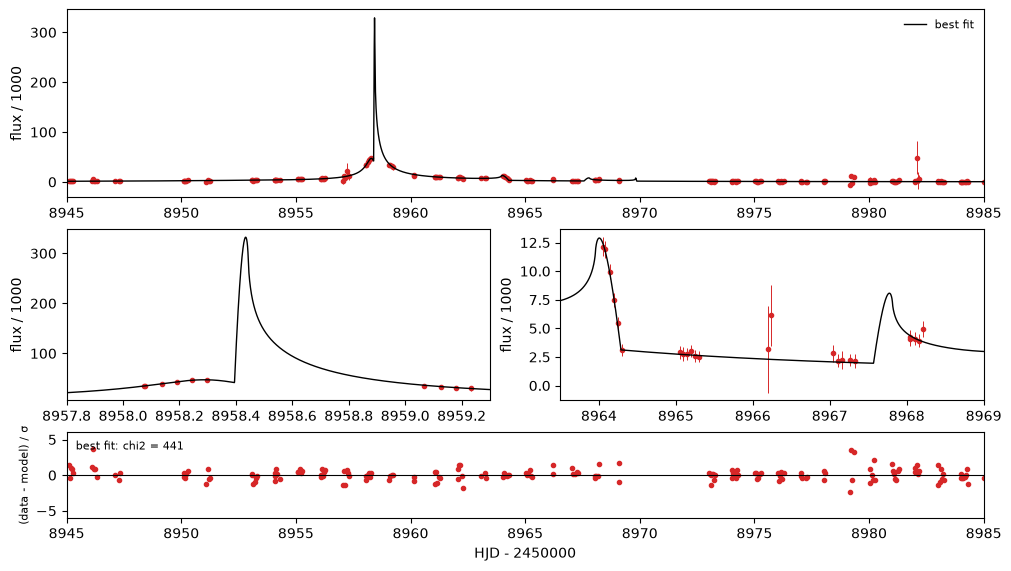

In [3]:
best = np.array([8958.772820862136, 1.781925899681274e-05, 35.57682566842092, 0.06098754202305941,
                 -1.8613489613591656, 3.476327053570743, -3.1665914421345507])
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
chi2_best = lenscape.model.chi2(be, best, data)
print(f"chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4] * 1e3:.2f}e-3, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6] * 1e3:.3f}e-3")


def plot_flux(sols, window=(8945, 8985), zooms=((8957.8, 8959.3), (8963.5, 8969.0))):
    # difference flux with the model of each solution (fluxes fitted per solution), two zooms on the anomaly and
    # one panel of normalised residuals per solution; the pySIS flux has an arbitrary zero point, so we stay in flux
    styles = ["-", ":", "--", "-."]
    fig = plt.figure(figsize=(10, 4.5 + 1.1 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    tm = np.linspace(*window, 6000)
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        m = (data.t > a) & (data.t < b)
        ax.errorbar(data.t[m], data.f[m] / 1e3, data.e[m] / 1e3, fmt="o", ms=3, lw=0.7, color="C3", zorder=2)
        tt = np.linspace(a, b, 3000)
        for (name, p), ls in zip(sols.items(), styles):
            A = lenscape.model.magnification(be, p, data)
            fs, fb = lenscape.model.fluxes(A, data)
            Am = be.lc(lenscape.model.clamp(p)[0], tt)
            ax.plot(tt, (fs[0] * Am + fb[0]) / 1e3, ls, color="k", lw=1, label=name, zorder=3)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
    top.legend(fontsize=8, frameon=False)
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, data)
        m = (data.t > window[0]) & (data.t < window[1])
        ax.plot(data.t[m], r[m], "o", ms=3, color="C3"); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-6, 6); ax.set_ylabel("(data - model) / σ", fontsize=8)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.0f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel("HJD - 2450000")
    return fig

plot_flux({"best fit": best});

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
at all. Any point above it is a failed fit, because a binary lens with a tiny *q* or a large *s* can always reproduce
the single lens.

In [4]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], -3.0], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun for u0 in (0.01, 0.03, 0.1, 0.3))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.0f}")

single-lens floor: Delta chi2 = 630


## 3. Stage 1: the lattice of the published map

These are the axes of Han et al.'s Fig. 2, measured from the figure. There are 43 points in log *s* from −0.795 to
+0.922 (step 0.041) and 54 points in log *q* from −3.69 to +1.17 (step 0.092). The steps are about 80 times wider than
those of the MOA-2022-BLG-091 map in `tutorial_first_map_research_note`. `lenscape.lattice` runs its five stages:

* seed grid;
* cell fits;
* lattice-point fits;
* neighbour refinement;
* outlier recalculation.

`06_maps` explains each stage. **Runtime: 59 minutes** (20 threads).

In [5]:
dls, dlq = 0.0409, 0.0917
logs1 = -0.7954 + dls * np.arange(43)
logq1 = -3.6877 + dlq * np.arange(54)
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")

def run_or_load(name, compute):
    if RECOMPUTE:
        m = compute()
        np.savez_compressed(f"data/kb200202_map_{name}.npz", **{k: m[k] for k in KEYS})
        return m
    return dict(np.load(f"data/kb200202_map_{name}.npz"))

map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best))
print(f"{map1['chi2'].shape} points, wall time {map1['wall'] / 60:.0f} min")

(43, 54) points, wall time 59 min


## 4. Stages 2 and 3: twice and four times the resolution

`lenscape.maps.densify` fits every point of a finer lattice from the nearest known solutions. It then refines the
map with the same neighbour and outlier stages as `lattice`. **Runtime: 93 minutes for 2× (85 × 107 points), 408
minutes for 4× (169 × 213 points).**

In [6]:
map2 = run_or_load("2x", lambda: lenscape.maps.densify(
    [map1], data, logs1[0] + dls / 2 * np.arange(85), logq1[0] + dlq / 2 * np.arange(107), best=best))
map4 = run_or_load("4x", lambda: lenscape.maps.densify(
    [map1, map2], data, logs1[0] + dls / 4 * np.arange(169), logq1[0] + dlq / 4 * np.arange(213), best=best))
for name, m in [("1x", map1), ("2x", map2), ("4x", map4)]:
    print(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]} points, wall time {m['wall'] / 60:.0f} min")

1x: 43 x 54 points, wall time 59 min
2x: 85 x 107 points, wall time 93 min
4x: 169 x 213 points, wall time 408 min


## 5. The three maps

All three maps are drawn against the same reference χ² (the 4× minimum), with a logarithmic colour scale up to
Δχ² = 1000. The single-lens floor is about 630, so a scale of 100, as used for MOA-2022-BLG-091, would show almost
nothing here.

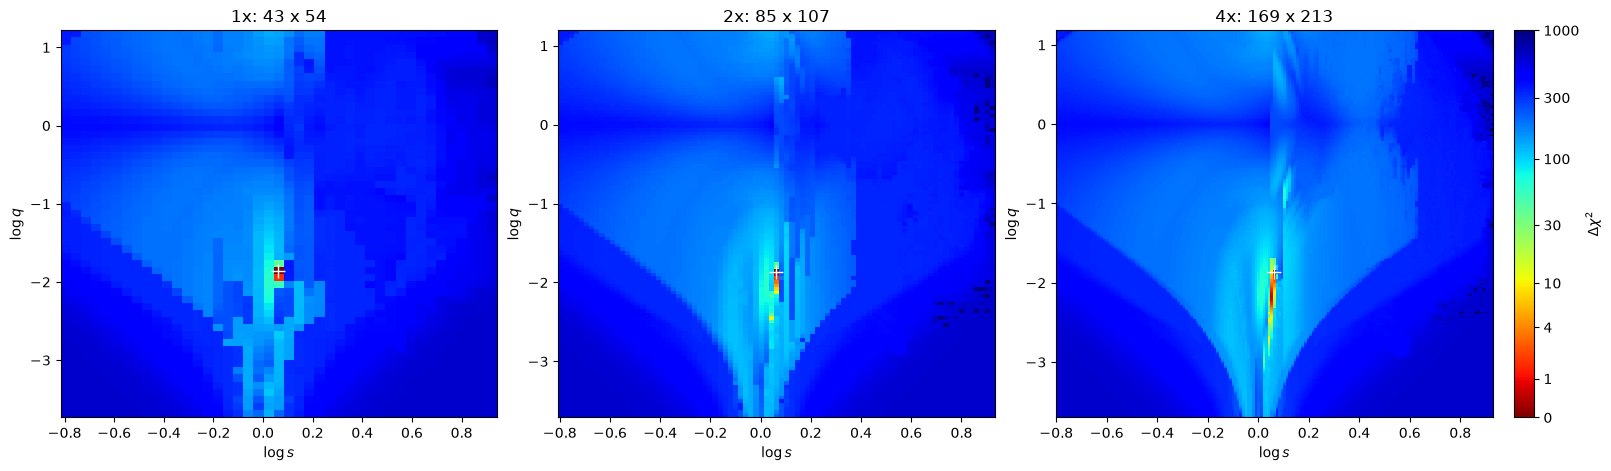

In [7]:
ref = map4["chi2_ref"]
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, (name, m) in zip(axs, [("1x", map1), ("2x", map2), ("4x", map4)]):
    figures.plot_map(m, ax=ax, vmax=1000, chi2_ref=ref, colorbar=(name == "4x"))
    ax.plot(best[3], best[4], "w+", ms=10)
    ax.set_title(f"{name}: {m['chi2'].shape[0]} x {m['chi2'].shape[1]}")

The three maps agree on what matters most:

* **One minimum.** All three put it at the same lattice point, log *s* = 0.064 and log *q* = −1.854 (white cross: the
  best fit). This is the "unique solution" of Han et al.
* **A V-shaped valley.** It opens downward from the minimum, with arms towards close and wide separations.

Each doubling adds structure. The arms become sharper and longer, and a band at Δχ² ≈ 200 appears at wide separations
(log *s* ≈ 0.3–0.6), which the 1× map barely shows. Section 7 explains why.

Next, the 4× map in the band style of the paper: Δχ² < *n* × (1, 4, 9, 16) with *n* = 10, and white above. We zoom
in on the central region.

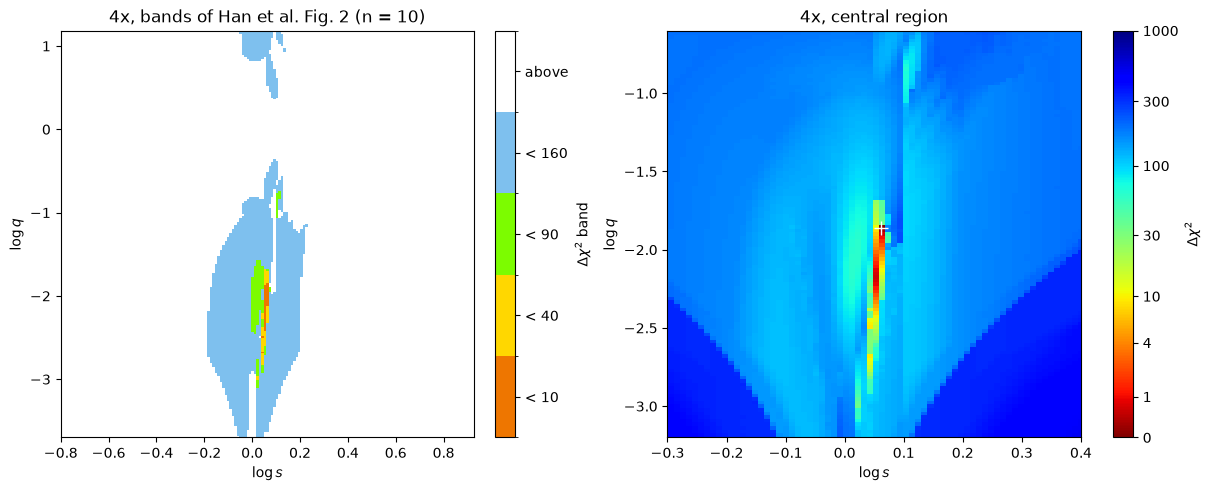

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
figures.plot_map(map4, ax=axs[0], bands=(10, 40, 90, 160))
axs[0].set_title("4x, bands of Han et al. Fig. 2 (n = 10)")
figures.plot_map(map4, ax=axs[1], vmax=1000)
axs[1].set_xlim(-0.3, 0.4); axs[1].set_ylim(-3.2, -0.6)
axs[1].plot(best[3], best[4], "w+", ms=10); axs[1].set_title("4x, central region");

**Comparison with the paper.** The shapes match: there is one minimum and a V opening downward, with arms on both
sides. The levels do not: the arms of Han et al. stay below Δχ² = 160 much farther out than ours. Their
re-reduced photometry has different error bars (*k* = 0.843 on their reduction, 2.27 on pySIS), which puts all
Δχ² values on a different scale, so only a constant factor between the two maps is meaningful. Fitted to the
published bands on the 1× map, that factor is about 2, and it is poorly determined. With it, 93 % of the paper's
coloured cells fall within one band of our 1× map. We found no published valley missing from our maps. Cold deep searches at the arm points, started without
neighbour information, gave worse χ² than the map, not better.

## 6. What the alternatives look like

How do the solutions along the valley fail? We pick the lowest map point in two regions and draw its light curve
next to the best fit:

* a **close** solution (log *s* < −0.1);
* a **wide** solution on the Δχ² ≈ 200 band (0.3 < log *s* < 0.6).

The map stores the five fitted parameters `(t0, u0, tE, alpha, log rho)` at each (*s*, *q*), and
`lenscape.fit.full_p` turns them into the seven-parameter vector.

best fit  log s = +0.061  log q = -1.861  tE =    35.6 d  t0 = 8958.77  Delta chi2 =    0.0
close     log s = -0.110  log q = -2.771  tE =   979.7 d  t0 = 8959.13  Delta chi2 =  112.3
wide      log s = +0.309  log q = -1.212  tE =   126.6 d  t0 = 8971.24  Delta chi2 =  181.1


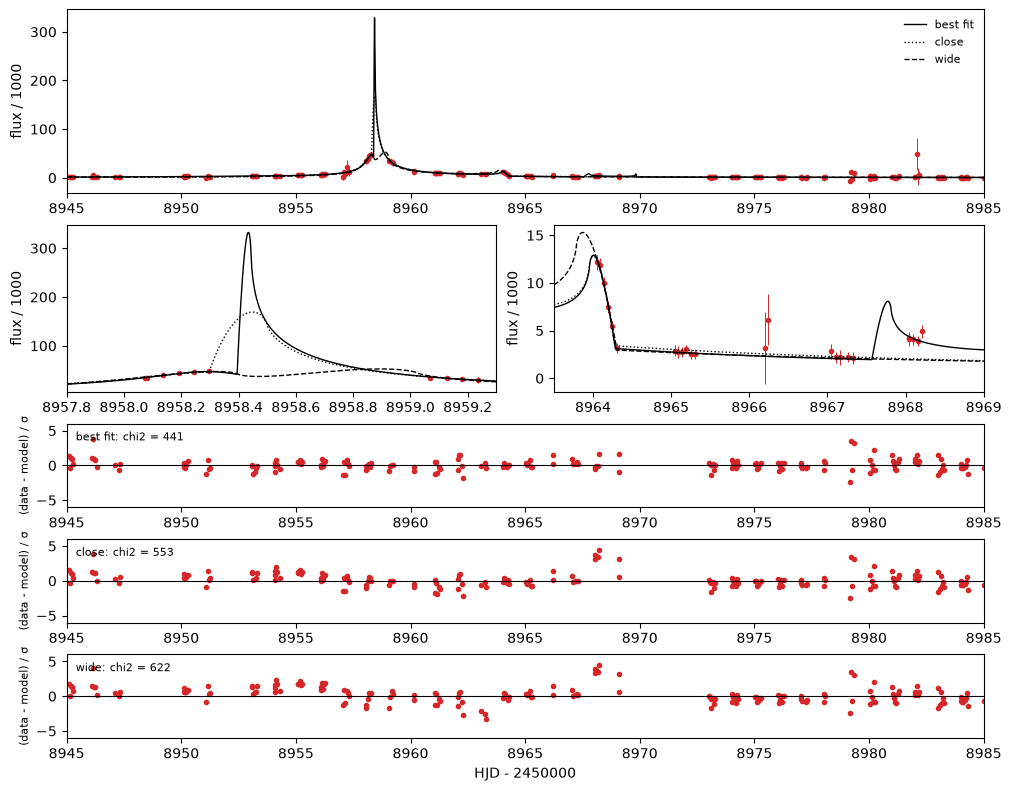

In [9]:
def lowest(m, s_range, q_range=(-9, 9)):
    si = np.where((m["logs"] > s_range[0]) & (m["logs"] < s_range[1]))[0]
    qi = np.where((m["logq"] > q_range[0]) & (m["logq"] < q_range[1]))[0]
    sub = m["chi2"][np.ix_(si, qi)]
    a, b = np.unravel_index(np.nanargmin(sub), sub.shape)
    i, j = si[a], qi[b]
    return np.array(lenscape.fit.full_p(m["pars"][i, j], m["logs"][i], m["logq"][j]))

sols = {"best fit": best, "close": lowest(map4, (-0.8, -0.1)), "wide": lowest(map4, (0.3, 0.6))}
for name, p in sols.items():
    print(f"{name:9s} log s = {p[3]:+.3f}  log q = {p[4]:+.3f}  tE = {p[2]:7.1f} d  t0 = {p[0]:.2f}  "
          f"Delta chi2 = {lenscape.model.chi2(be, p, data) - chi2_best:6.1f}")
plot_flux(sols);

The data are sparse: no point falls on the sharp caustic spike of the best fit at HJD′ 8958.4, so the three models
differ most where there are no data. The alternatives lose where there are data. The close solution misses the third
feature at HJD′ 8968 (residuals of −3 to −4σ there). The wide solution misses that feature too, and it also gets the
shape of the rise between 8953 and 8963 wrong. Together this costs Δχ² ≈ 110 and ≈ 180. With one telescope and
gaps of several hours, a map is the only way to see that nothing else fits. The close solution has
*t*ₑ ≈ 980 d, at lenscape's upper bound of 1000 d. A faint source with a very long timescale is a way of producing a
weak, broad anomaly, and Section 7 comes back to it.

## 7. Limits of the maps

### 7.1 Coarse maps miss low-χ² solutions

Every point of the 1× and 2× lattices is also a point of the 4× lattice. Comparing the values at these shared points
shows how much each doubling found that the coarser map missed:

In [10]:
for name, m, step in [("1x", map1, 4), ("2x", map2, 2)]:
    c4 = map4["chi2"][::step, ::step]
    diff = m["chi2"] - c4
    for label, sel in [("Delta chi2 < 160 at 4x", c4 - ref < 160), ("all points", np.isfinite(c4))]:
        print(f"{name} vs 4x, {label:22s}: {sel.sum():5d} points, coarser map higher by > 1 at "
              f"{100 * (diff[sel] > 1).mean():3.0f} %, by > 10 at {100 * (diff[sel] > 10).mean():3.0f} %, "
              f"lower by > 1 at {100 * (diff[sel] < -1).mean():.0f} %")

1x vs 4x, Delta chi2 < 160 at 4x:   258 points, coarser map higher by > 1 at  72 %, by > 10 at  63 %, lower by > 1 at 0 %
1x vs 4x, all points            :  2322 points, coarser map higher by > 1 at  41 %, by > 10 at  34 %, lower by > 1 at 0 %
2x vs 4x, Delta chi2 < 160 at 4x:   988 points, coarser map higher by > 1 at  30 %, by > 10 at  23 %, lower by > 1 at 0 %
2x vs 4x, all points            :  9095 points, coarser map higher by > 1 at  29 %, by > 10 at  23 %, lower by > 1 at 0 %


The finer map is never worse at a shared point, because densify always tries the coarse solution there as well. It is
often much better: in the region that matters (Δχ² < 160 at 4×), 63 % of the 1× points and 23 % of the 2× points
were more than 10 too high.

The coarse maps are not wrong where they found the right solution, but they often did not find it. The cause is the
neighbour refinement, the stage that spreads good solutions over the map. A neighbour's solution is a good start only
if the solution changes little from one lattice point to the next. On the MOA-2022-BLG-091 lattice (steps of 0.0005
dex) it does. Here the steps are 0.04 dex in *s* and 0.09 dex in *q*, and a narrow branch of solutions can pass
between two lattice points without either point's fit starting close to it. Halving the step lets the branch spread
further.

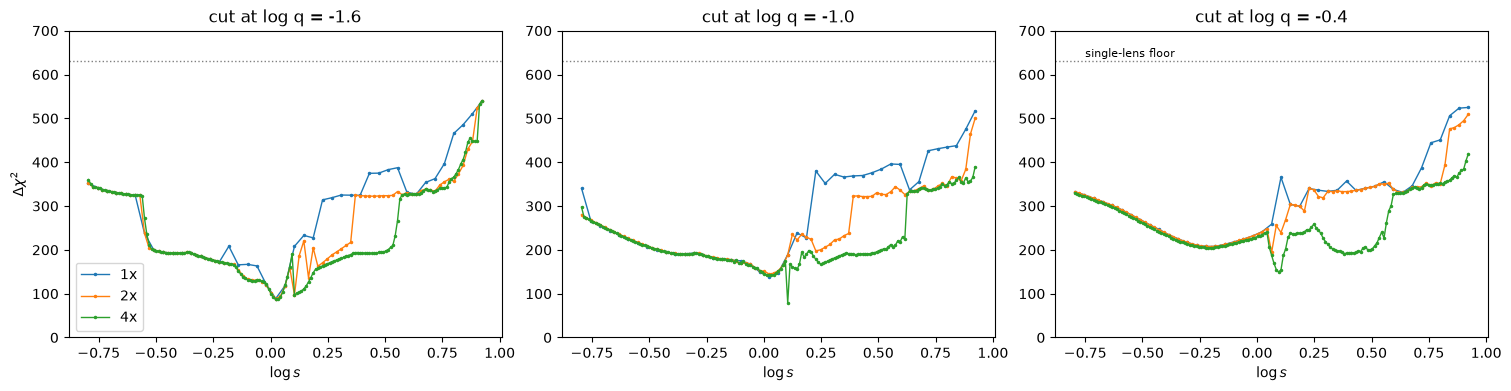

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, lq in zip(axs, [-1.6, -1.0, -0.4]):
    for name, m in [("1x", map1), ("2x", map2), ("4x", map4)]:
        j = np.argmin(abs(m["logq"] - lq))
        ax.plot(m["logs"], m["chi2"][:, j] - ref, ".-", ms=3, lw=1, label=name)
    ax.axhline(floor, color="grey", ls=":", lw=1)
    ax.set_ylim(0, 700); ax.set_xlabel(r"$\log s$"); ax.set_title(f"cut at log q = {lq}")
axs[0].set_ylabel(r"$\Delta\chi^2$"); axs[0].legend(); axs[2].text(-0.75, floor + 10, "single-lens floor", fontsize=8);

The cuts show the mechanism. On the wide side (log *s* > 0.2) there is a branch at Δχ² ≈ 190 that ends in a step up
to ≈ 330:

| map | the step is at about |
|---|---|
| 1× | log *s* ≈ 0.2 |
| 2× | log *s* ≈ 0.35 |
| 4× | log *s* ≈ 0.55 |

Each doubling carries the branch farther out, so **the 4× map is not converged there either.** Two separate tests on
this event point the same way:

* An independent 4× densify of the box 0.2 < log *s* < 0.7, −2.5 < log *q* < 0.3, started from a different 2× map,
  differs from this one by more than 1 at about half of the shared points, in both directions.
* A deep refit of 150 points of that box (every neighbour solution, several source sizes) lowered 14 % of them by more
  than 1 and 2 % by more than 10.

The values in this region (Δχ² ≈ 150–350) depend on the path the refinement took, not just on the data. We also tried
following the branch with continuation steps (short fits along the line to the next lattice point). This recovers
most of it but costs as much as a 4× densify, so lenscape does not do it by default.

The same happens close to the minimum. The valley below the minimum is narrower in log *s* than one step of the 1×
lattice, and each doubling extends the region with Δχ² < 40:

In [12]:
for name, m in [("1x", map1), ("2x", map2), ("4x", map4)]:
    d = m["chi2"] - ref
    S, Q = np.meshgrid(m["logs"], m["logq"], indexing="ij")
    sel = d < 40
    print(f"{name}: Delta chi2 < 40 at {sel.sum():3d} points, log s {S[sel].min():+.3f} .. {S[sel].max():+.3f}, "
          f"log q {Q[sel].min():+.2f} .. {Q[sel].max():+.2f}")

1x: Delta chi2 < 40 at   2 points, log s +0.064 .. +0.064, log q -1.95 .. -1.85
2x: Delta chi2 < 40 at  10 points, log s +0.043 .. +0.064, log q -2.45 .. -1.81
4x: Delta chi2 < 40 at  92 points, log s +0.023 .. +0.064, log q -3.00 .. -1.69


At 1× only the minimum and one neighbour lie below 40. At 4× the valley reaches down to log *q* = −3.0, and among the
2× points that lie below 40 at 4×, more than half were too high by more than 10 at 2×. Narrow valleys of this kind
are what the published maps show. **For your own event,** check whether the bands you care about still change from
one doubling to the next before you interpret their extent.

### 7.2 The floor region is neither refined nor converged

`densify` refines only points within Δχ² < 500 of the minimum, together with their neighbours (`dchi2_cut=5.0` in
units of 100). Points above that are left as their first fit found them. Since the single-lens floor is about 630,
some of these values are plainly failed fits:

In [13]:
for name, m in [("1x", map1), ("2x", map2), ("4x", map4)]:
    d = m["chi2"] - ref
    tE = np.abs(m["pars"][..., 2])
    print(f"{name}: above the single-lens floor {(d > floor + 1).sum():4d} points ({100 * (d > floor + 1).mean():.1f} %), "
          f"max Delta chi2 {d.max():5.0f};  tE at the 1000 d bound: {100 * (tE > 990).mean():.0f} % of points")

1x: above the single-lens floor    6 points (0.3 %), max Delta chi2   657;  tE at the 1000 d bound: 20 % of points
2x: above the single-lens floor   66 points (0.7 %), max Delta chi2  5793;  tE at the 1000 d bound: 21 % of points
4x: above the single-lens floor  199 points (0.6 %), max Delta chi2  5770;  tE at the 1000 d bound: 21 % of points


In the 2× and 4× maps, 66 and 199 points lie above the single-lens floor, all at log *s* ≥ 0.70, far from any
valley. Some of them reach Δχ² ≈ 5800. These are failed fits that the cut kept out of refinement (the dark specks at
the right edge of the maps in Section 5). They do not affect the valleys. The 1× map, where `lattice` refines all
points (its `dchi2_cut` is off by default), has only 6 such points, at most 27 above the floor.

About a fifth of all points end at the timescale bound of 1000 d. This is the faint-source, long-*t*ₑ branch: far
from the true (*s*, *q*), the best a binary lens can do is a weak, broad perturbation of a very faint source. The
bound itself matters little here, because these points lie at Δχ² ≈ 100–630. But it means that the long-*t*ₑ
minimum at the bound is a property of the fit box, not of the data.

### 7.3 Cost

The 4× map took 408 minutes for 36 000 points:

* the neighbour refinement checked 108 000 points;
* 49 points hit `max_refits=30`;
* the outlier stage was still improving 36 points per pass when its limit of 10 passes stopped it.

Wide lattices are the hard case for neighbour propagation. A cheaper route to a reliable picture of the valleys is to
compute the coarse map over the whole range, then densify only a box around the region of interest. Section 7.1 shows
why the coarse map alone is not enough.

## 8. Summary and using this notebook for your own event

* With the paper's lattice and all defaults, lenscape finds the published unique solution and its V-shaped valley.
  The minimum sits at the same lattice point in all three maps.
* The maps are not converged at this resolution. Each doubling lowers the map along narrow branches, both in the
  valley below the minimum (Δχ² < 40 reaches log *q* = −2.45 at 2× and −3.0 at 4×) and in the wide-separation branch at
  Δχ² ≈ 200. Coarse maps are upper bounds on the profile χ²: before you interpret the extent of a valley, check
  whether it still changes from one doubling to the next.
* Points far above the minimum (Δχ² > 500) are not refined, and some are worse than the single-lens model.

To run the same steps on another event:

1. Replace the CSV with your photometry, one `(t, flux, flux_err)` triple per data set, with error bars rescaled.
2. Replace `best` with a full fit (`lenscape.fit_full`).
3. Choose the axes of the first lattice.
4. Set `RECOMPUTE = True`.

Start coarse, then densify around the region you care about rather than over the whole map: the cost of densify grows
with the number of points within `dchi2_cut`.

**References.** Han, C., et al. 2026, arXiv:2601.13450. Yee, J. C., et al. 2012, ApJ, 755, 102.